# Session 3 : les exercices expliqués pas à pas

**Ton premier réseau de neurones et la backpropagation** (MSA-DATB09-03, Neural Networks & Deep Learning Foundations)

Ce notebook reprend les **3 exercices** de la session 3 (slides 5, 8 et 16), avec toutes les formules du cours dont ils ont besoin :

| Exercice | Sujet | Ce qu'on apprend | Lien avec le TP03 |
|---|---|---|---|
| 1 | Le réseau XOR à la main | pourquoi une couche cachée résout ce qu'un neurone seul ne peut pas faire | Partie A |
| 2 | Formes et nombre de paramètres | lire et compter les poids d'un réseau | Exercice 11 |
| 3 | Forward et backward à la main | la **backpropagation**, couche par couche | Partie B |

**Comment le lire.** Pour chaque question, tu trouveras :

1. 📖 **Le cours** : la formule, ce qu'elle veut dire symbole par symbole, et d'où elle vient.
2. ✍️ **Le calcul à la main** : exactement ce que tu écrirais sur ta copie.
3. 💻 **La vérification en Python** : on refait le calcul avec NumPy pour être sûr du résultat.

Exécute les cellules **dans l'ordre**, de haut en bas (Shift + Entrée).

## 0. Rappel de la session 2 et nouveau vocabulaire

**Ce qu'on savait déjà (un seul neurone)** :

- score : $z = w^\top x + b$ ; probabilité : $a = \sigma(z) = \dfrac{1}{1 + e^{-z}}$ ;
- dérivée de la sigmoïde : $\sigma'(z) = a(1 - a)$, au maximum 0.25 (atteint en $z = 0$) ;
- gradient de la log loss : $\dfrac{\partial \mathcal{L}}{\partial w} = (a - y)\,x$, c'est-à-dire **erreur × entrée**.

**Le problème** : un neurone seul trace **une seule droite**. Impossible de séparer les données du XOR (ou les « moons ») avec une droite. La solution de la session 3 : **empiler des neurones en couches**.

**Le nouveau vocabulaire** :

| Symbole | Ce que c'est, en clair |
|---|---|
| couche $l$ | un « étage » de neurones. La couche 0 est l'entrée $x$, la dernière est la sortie. Entre les deux : les **couches cachées** |
| $[l]$ en exposant | le **numéro de la couche** (ce n'est **pas** une puissance !). $W^{[1]}$ = les poids de la couche 1 |
| $n^{[l]}$ | le nombre de neurones de la couche $l$. $n^{[0]}$ = nombre d'entrées. Un réseau « 2-3-1 » a $n^{[0]} = 2$, $n^{[1]} = 3$, $n^{[2]} = 1$ |
| $W^{[l]}$ | la **matrice** des poids de la couche $l$ : une **ligne par neurone**, une **colonne par entrée** |
| $b^{[l]}$ | le vecteur des biais de la couche $l$ : un biais par neurone |
| $z^{[l]}$, $a^{[l]}$ | les scores et les sorties (activations) de la couche $l$ |
| $h$ | « hidden » : la sortie de la couche cachée (ici $h = a^{[1]}$) |
| $\hat{y}$ | « y chapeau » : la prédiction du réseau (sa sortie finale) |
| $dz$, $dW$, $da$... | le **gradient** de la loss par rapport à cette quantité : $dW^{[1]} = \dfrac{\partial \mathcal{L}}{\partial W^{[1]}}$ |
| $\odot$ | le produit **élément par élément** : $(2, 3) \odot (4, 5) = (8, 15)$ |
| $M^\top$ | la **transposée** : on échange lignes et colonnes |

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Afficher les tableaux NumPy avec 4 décimales, c'est plus lisible
np.set_printoptions(precision=4, suppress=True)


def step(z):
    # la "marche" du perceptron : 1 si z >= 0, sinon 0
    return (np.asarray(z) >= 0).astype(int)


def sigmoid(z):
    # sigma(z) = 1 / (1 + e^(-z))
    return 1 / (1 + np.exp(-z))

---
# Exercice 1 : le réseau XOR à la main

> **Énoncé (slide 5)** : activation marche, les poids de la session 1.
>
> 1. Pour les 4 entrées $(0, 0), (0, 1), (1, 0), (1, 1)$, calculer $h_1$, $h_2$ (activation marche), puis $\hat{y}$. Le réseau calcule-t-il XOR ?
> 2. Remplacer chaque marche par une sigmoïde et multiplier tous les poids et biais par 10. Calculer $h_1, h_2, \hat{y}$ pour $x = (0, 1)$. Utiliser $\sigma(5) \approx 0.993$ et $\sigma(4.87) \approx 0.992$.

Le réseau (chaque neurone caché reçoit **les deux** entrées $x_1$ et $x_2$) :

```
   entrées       couche cachée (2 neurones)                 sortie (1 neurone)

   x1 ---+--->  h1 = OR    w = (1, 1),   b = -0.5   ---+
          \ /                                           +--->  y_hat = AND   w = (1, 1), b = -1.5
          / \                                           |
   x2 ---+--->  h2 = NAND  w = (-1, -1), b = 1.5    ---+
```

## 📖 Le cours : pourquoi deux couches ?

**Le XOR (« ou exclusif »)** vaut 1 quand **exactement une** des deux entrées vaut 1. Voici sa table, avec les portes logiques dont on va se servir :

| $x_1$ | $x_2$ | OR (au moins un) | NAND (pas les deux) | AND (les deux) | **XOR** |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 1 | 0 | **0** |
| 0 | 1 | 1 | 1 | 0 | **1** |
| 1 | 0 | 1 | 1 | 0 | **1** |
| 1 | 1 | 1 | 0 | 1 | **0** |

**Le problème** : sur un dessin, les points $(0, 1)$ et $(1, 0)$ (classe 1) sont sur une diagonale, $(0, 0)$ et $(1, 1)$ (classe 0) sur l'autre. **Aucune droite** ne sépare les deux classes, donc un neurone seul (qui trace une droite) ne peut pas calculer XOR.

**L'astuce** : regarde les colonnes. XOR vaut 1 exactement quand OR vaut 1 **et** NAND vaut 1 :

$$\text{XOR}(x_1, x_2) = \text{AND}\big(\text{OR}(x_1, x_2),\ \text{NAND}(x_1, x_2)\big)$$

Et OR, NAND, AND se font chacun avec **un** neurone (une droite). D'où le réseau :

- **couche cachée** : un neurone OR et un neurone NAND, chacun trace **sa** droite ;
- **couche de sortie** : un neurone AND qui combine leurs réponses.

**Chaque neurone fait exactement ce qu'on connaît** : $z = w_1 x_1 + w_2 x_2 + b$, puis activation. Ici l'activation est la **marche** :

$$\text{step}(z) = \begin{cases} 1 & \text{si } z \ge 0 \\ 0 & \text{sinon} \end{cases}$$

## ✍️ Question 1 : le calcul à la main

Les trois formules, en remplaçant les poids :

- neurone OR : $z_1 = 1 \times x_1 + 1 \times x_2 - 0.5 = x_1 + x_2 - 0.5$, puis $h_1 = \text{step}(z_1)$
- neurone NAND : $z_2 = -1 \times x_1 - 1 \times x_2 + 1.5 = -x_1 - x_2 + 1.5$, puis $h_2 = \text{step}(z_2)$
- neurone AND (ses entrées sont $h_1$ et $h_2$, **pas** $x$ !) : $z = h_1 + h_2 - 1.5$, puis $\hat{y} = \text{step}(z)$

**Exemple détaillé pour $x = (1, 1)$** :

1. $z_1 = 1 + 1 - 0.5 = 1.5 \ge 0$, donc $h_1 = 1$ (au moins une entrée vaut 1)
2. $z_2 = -1 - 1 + 1.5 = -0.5 < 0$, donc $h_2 = 0$ (les deux valent 1, donc NAND dit 0)
3. $z = 1 + 0 - 1.5 = -0.5 < 0$, donc $\hat{y} = 0$ ✓ (XOR(1, 1) = 0)

**Les 4 entrées** :

| $x$ | $z_1$ | $h_1$ | $z_2$ | $h_2$ | $z = h_1 + h_2 - 1.5$ | $\hat{y}$ | XOR attendu |
|---|---|---|---|---|---|---|---|
| (0, 0) | -0.5 | 0 | 1.5 | 1 | -0.5 | **0** | 0 ✓ |
| (0, 1) | 0.5 | 1 | 0.5 | 1 | 0.5 | **1** | 1 ✓ |
| (1, 0) | 0.5 | 1 | 0.5 | 1 | 0.5 | **1** | 1 ✓ |
| (1, 1) | 1.5 | 1 | -0.5 | 0 | -0.5 | **0** | 0 ✓ |

**Oui, le réseau calcule XOR** : $\hat{y} = (0, 1, 1, 0)$ pour les 4 entrées.

## 💻 Vérification en Python : une couche en une ligne

En code (NumPy et PyTorch), on met **un exemple par ligne** : `X` a la forme $(m, n^{[0]})$, ici $(4, 2)$. Dans les slides, au contraire, un exemple est une **colonne** et on écrit $z = Wx + b$. Pour passer d'une convention à l'autre, on transpose tout (slide 10) :

$$Z^{[l]} = A^{[l-1]}\, W^{[l]\top} + b^{[l]} \qquad \text{forme } (m, n^{[l]})$$

En Python : `X @ W.T + b`. Le résultat a **une ligne par exemple** et **une colonne par neurone**. C'est exactement ce que fait `nn.Linear` de PyTorch.

In [13]:
def dense(X, W, b, activation):
    # Une couche : chaque ligne de X est un exemple, chaque ligne de W est un neurone
    return activation(X @ W.T + b)


X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])   # les 4 entrées, une par ligne
y_xor = np.array([0, 1, 1, 0])                       # le XOR attendu

W1 = np.array([[1, 1],       # ligne 0 : le neurone OR
               [-1, -1]])    # ligne 1 : le neurone NAND
b1 = np.array([-0.5, 1.5])
W2 = np.array([[1, 1]])      # le neurone AND (une seule ligne : un seul neurone)
b2 = np.array([-1.5])

H = dense(X_xor, W1, b1, step)       # couche cachée, forme (4, 2)
y_hat = dense(H, W2, b2, step)       # sortie, forme (4, 1)

print("   x     | h1 h2 | y_hat | XOR")
for i in range(4):
    print(f" {X_xor[i]}  |  {H[i, 0]}  {H[i, 1]} |   {y_hat[i, 0]}   |  {y_xor[i]}")
print("\nLe réseau calcule XOR :", np.array_equal(y_hat.ravel(), y_xor))

   x     | h1 h2 | y_hat | XOR
 [0 0]  |  0  1 |   0   |  0
 [0 1]  |  1  1 |   1   |  1
 [1 0]  |  1  1 |   1   |  1
 [1 1]  |  1  0 |   0   |  0

Le réseau calcule XOR : True


## 📖 Ce que fait la couche cachée : une nouvelle représentation (slide 6)

Regarde la colonne $(h_1, h_2)$ du tableau : la couche cachée **transforme** chaque point $x$ en un nouveau point $h$.

| entrée $x$ | point caché $h = (h_1, h_2)$ | XOR |
|---|---|---|
| (0, 0) | (0, 1) | 0 |
| (0, 1) et (1, 0) | (1, 1) | 1 |
| (1, 1) | (1, 0) | 0 |

Dans ce **nouvel espace**, les deux classes **se séparent avec une droite** ($h_1 + h_2 - 1.5 = 0$) : le neurone de sortie n'a plus qu'à faire son travail habituel.

➡️ **L'idée clé du deep learning** : une couche cachée fabrique de **nouvelles caractéristiques** (features) dans lesquelles le problème devient facile pour le dernier neurone. Ici on a choisi les poids à la main ; à l'entraînement, le réseau les trouvera **tout seul**.

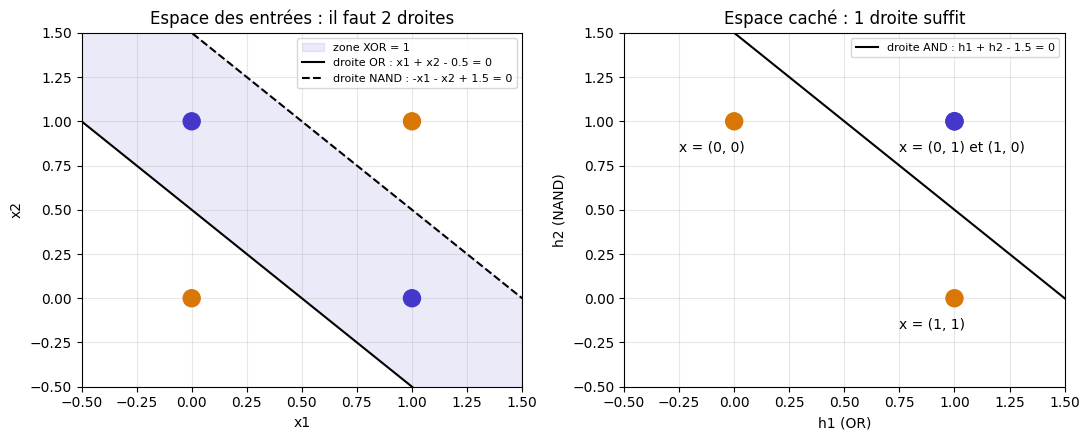

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
couleurs = ["#d97706" if c == 0 else "#4338ca" for c in y_xor]
t = np.linspace(-0.5, 1.5, 50)

# A gauche : l'espace des entrées x, avec les droites des deux neurones cachés
ax = axes[0]
ax.fill_between(t, 0.5 - t, 1.5 - t, color="#4338ca", alpha=0.1, label="zone XOR = 1")
ax.plot(t, 0.5 - t, "k-", label="droite OR : x1 + x2 - 0.5 = 0")
ax.plot(t, 1.5 - t, "k--", label="droite NAND : -x1 - x2 + 1.5 = 0")
ax.scatter(X_xor[:, 0], X_xor[:, 1], c=couleurs, s=150, zorder=3)
ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="x1", ylabel="x2",
       title="Espace des entrées : il faut 2 droites")
ax.legend(loc="upper right", fontsize=8)

# A droite : l'espace caché h, où une seule droite suffit
ax = axes[1]
ax.plot(t, 1.5 - t, "k-", label="droite AND : h1 + h2 - 1.5 = 0")
ax.scatter(H[:, 0], H[:, 1], c=couleurs, s=150, zorder=3)
for nom, (h1, h2) in {"x = (0, 0)": (0, 1), "x = (0, 1) et (1, 0)": (1, 1), "x = (1, 1)": (1, 0)}.items():
    ax.annotate(nom, (h1, h2), textcoords="offset points", xytext=(-40, -22))
ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="h1 (OR)", ylabel="h2 (NAND)",
       title="Espace caché : 1 droite suffit")
ax.legend(loc="upper right", fontsize=8)

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 📖 Question 2 : pourquoi remplacer la marche par une sigmoïde ×10 ?

**Pourquoi la sigmoïde ?** La marche est plate partout : sa pente vaut 0, donc **impossible d'entraîner** le réseau par descente de gradient (on ne sait pas dans quel sens corriger). La sigmoïde est une marche **adoucie**, qui a une pente partout (session 2).

**Pourquoi multiplier par 10 ?** Si on multiplie **tous** les poids et biais d'un neurone par 10, son score est multiplié par 10 :

$$z' = (10\,w_1)\,x_1 + (10\,w_2)\,x_2 + 10\,b = 10 \times (w_1 x_1 + w_2 x_2 + b) = 10\,z$$

Or $\sigma(10\,z)$ est une sigmoïde **beaucoup plus raide**, presque une marche. Exemple avec $z = 0.5$ : $\sigma(0.5) \approx 0.62$ (réponse floue), mais $\sigma(10 \times 0.5) = \sigma(5) \approx 0.993$ (presque 1). On garde donc le comportement du réseau à marches, mais avec une fonction dérivable.

Les nouveaux poids : OR : $w = (10, 10)$, $b = -5$ ; NAND : $w = (-10, -10)$, $b = 15$ ; AND : $w = (10, 10)$, $b = -15$.

## ✍️ Le calcul à la main pour $x = (0, 1)$

Ici $x_1 = 0$ et $x_2 = 1$. Chaque neurone a ses propres poids $w = (w_1, w_2)$ et son biais $b$ (donnés juste au-dessus). Pour chacun : la formule avec les variables, puis chaque chiffre écrit au-dessus du nom de sa variable.

**Neurone caché 1 (OR)**, avec $w = (10, 10)$ et $b = -5$ :

$$z_1 = w_1\,x_1 + w_2\,x_2 + b = \underbrace{10}_{w_1} \times \underbrace{0}_{x_1} + \underbrace{10}_{w_2} \times \underbrace{1}_{x_2} + \underbrace{(-5)}_{b} = 5 \qquad h_1 = \sigma(5) \approx \mathbf{0.993}$$

**Neurone caché 2 (NAND)**, avec $w = (-10, -10)$ et $b = 15$ :

$$z_2 = w_1\,x_1 + w_2\,x_2 + b = \underbrace{(-10)}_{w_1} \times \underbrace{0}_{x_1} + \underbrace{(-10)}_{w_2} \times \underbrace{1}_{x_2} + \underbrace{15}_{b} = 5 \qquad h_2 = \sigma(5) \approx \mathbf{0.993}$$

**Neurone de sortie (AND)**, avec $w = (10, 10)$ et $b = -15$. ⚠️ Ses entrées sont $h_1$ et $h_2$, pas $x_1$ et $x_2$ :

$$z = w_1\,h_1 + w_2\,h_2 + b = \underbrace{10}_{w_1} \times \underbrace{0.993}_{h_1} + \underbrace{10}_{w_2} \times \underbrace{0.993}_{h_2} + \underbrace{(-15)}_{b} = 19.87 - 15 \approx 4.87 \qquad \hat{y} = \sigma(4.87) \approx \mathbf{0.992}$$

(Avec la valeur arrondie 0.993 on trouve 19.86 ; l'énoncé utilise la valeur plus précise $\sigma(5) = 0.99331$, ce qui donne 19.87. Ça ne change rien au résultat.)

**Conclusion** : $\hat{y} \approx 0.992$, très proche de 1 = XOR(0, 1). Le réseau à sigmoïdes donne **presque les mêmes réponses** que le réseau à marches, mais il est **dérivable**, donc **entraînable**.

Pour x = (0, 1) :
  z1 = z2 = [5. 5.]  ->  h1, h2 = [0.9933 0.9933]
  z = 4.866  ->  y_hat = 0.9924

Les 4 entrées :
  x = [0 0]  ->  y_hat = 0.0072   (XOR = 0)
  x = [0 1]  ->  y_hat = 0.9924   (XOR = 1)
  x = [1 0]  ->  y_hat = 0.9924   (XOR = 1)
  x = [1 1]  ->  y_hat = 0.0072   (XOR = 0)


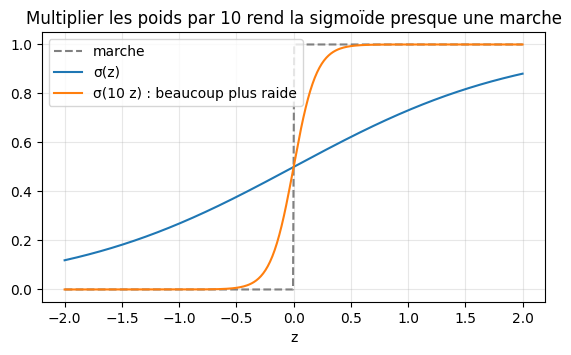

In [15]:
# Même réseau, sigmoïdes, tous les poids et biais multipliés par 10
H_sig = dense(X_xor, 10 * W1, 10 * b1, sigmoid)
y_sig = dense(H_sig, 10 * W2, 10 * b2, sigmoid)

print("Pour x = (0, 1) :")
print("  z1 = z2 =", (X_xor[1] @ (10 * W1).T + 10 * b1), " ->  h1, h2 =", H_sig[1])
print("  z =", round(float(H_sig[1] @ (10 * W2).T[:, 0] + 10 * b2[0]), 3), " ->  y_hat =", round(float(y_sig[1, 0]), 4))

print("\nLes 4 entrées :")
for i in range(4):
    print(f"  x = {X_xor[i]}  ->  y_hat = {y_sig[i, 0]:.4f}   (XOR = {y_xor[i]})")

# La sigmoïde x10 ressemble beaucoup plus à une marche
z_grille = np.linspace(-2, 2, 400)
plt.figure(figsize=(6.5, 3.5))
plt.plot(z_grille, step(z_grille), "--", color="gray", label="marche")
plt.plot(z_grille, sigmoid(z_grille), label="σ(z)")
plt.plot(z_grille, sigmoid(10 * z_grille), label="σ(10 z) : beaucoup plus raide")
plt.xlabel("z"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Multiplier les poids par 10 rend la sigmoïde presque une marche")
plt.show()

## 📖 À savoir : pourquoi une activation non linéaire est indispensable (slide 11)

Et si on enlevait la marche (ou la sigmoïde) entre les deux couches ? On aurait deux couches « linéaires » à la suite :

$$z^{[2]} = W^{[2]}\big(W^{[1]}x + b^{[1]}\big) + b^{[2]} = \underbrace{W^{[2]}W^{[1]}}_{W'}\,x + \underbrace{W^{[2]}b^{[1]} + b^{[2]}}_{b'} = W'x + b'$$

On a juste développé (distribué $W^{[2]}$ sur la parenthèse). Résultat : deux couches linéaires **équivalent à une seule** couche linéaire $W'x + b'$. Elle trace **une seule droite**, peu importe le nombre de couches empilées.

➡️ C'est l'activation **non linéaire** (sigmoïde aujourd'hui, ReLU en session 5) **entre** les couches qui permet au réseau de **courber** sa frontière.

⚠️ **Piège classique** : oublier l'activation entre deux `nn.Linear` en PyTorch. Le code tourne sans erreur, mais le modèle reste linéaire.

Vérifions avec les poids du XOR : sans la marche, que devient le réseau ?

In [16]:
W_prime = W2 @ W1          # W' = W[2] W[1]
b_prime = W2 @ b1 + b2     # b' = W[2] b[1] + b[2]
print("W' =", W_prime, "   b' =", b_prime)

sans_activation = (X_xor @ W1.T + b1) @ W2.T + b2      # deux couches sans activation
une_seule_couche = X_xor @ W_prime.T + b_prime          # une seule couche W', b'
print("Deux couches sans activation :", sans_activation.ravel())
print("Une seule couche (W', b')     :", une_seule_couche.ravel())

W' = [[0 0]]    b' = [-0.5]
Deux couches sans activation : [-0.5 -0.5 -0.5 -0.5]
Une seule couche (W', b')     : [-0.5 -0.5 -0.5 -0.5]


Spectaculaire : sans activation, le réseau XOR devient $W' = (0, 0)$ et $b' = -0.5$. Il répond **-0.5 pour toutes les entrées** : il ne sait plus rien faire du tout !

> ✅ **À retenir (exercice 1)**
>
> - Un neurone = une droite. XOR = AND(OR, NAND) : 2 neurones cachés tracent 2 droites, le neurone de sortie les combine.
> - La couche cachée crée une **nouvelle représentation** $h$ où le problème devient séparable par une droite.
> - On remplace la marche par une sigmoïde pour pouvoir **entraîner** le réseau (il faut une pente).
> - Sans activation non linéaire entre les couches, tout le réseau se réduit à **une seule** couche linéaire.

---
# Exercice 2 : formes et nombre de paramètres

> **Énoncé (slide 8)**
>
> 1. Le réseau 2-3-1 de la figure : donner les formes de $W^{[1]}, b^{[1]}, W^{[2]}, b^{[2]}$ et le nombre total de paramètres.
> 2. Un réseau pour des images de chiffres 28×28 en niveaux de gris : 784 entrées, une couche cachée de 128 neurones, 10 sorties (784-128-10). Mêmes questions.
> 3. Quelle couche contient la plupart des paramètres du réseau 784-128-10, et pourquoi ?

Le réseau 2-3-1 de la slide 7 :

```
   couche 0 (entrée)     couche 1 (cachée)      couche 2 (sortie)
      n[0] = 2               n[1] = 3               n[2] = 1

                          +--> a1[1] --+
       x1 ---+            |            |
              >-----------+--> a2[1] --+------>  a[2]
       x2 ---+            |            |
                          +--> a3[1] --+

   (chaque entrée est reliée à CHAQUE neurone caché, chaque neurone caché à la sortie)
```

## 📖 Le cours : la forme des matrices de poids (slide 7)

**Un neurone de la couche $l$ a un poids par neurone de la couche précédente** $l - 1$ (une connexion = un poids), plus un biais. On range les poids de tous les neurones de la couche dans une matrice, **une ligne par neurone** :

$$W^{[l]} \text{ a la forme } \big(n^{[l]},\ n^{[l-1]}\big) \qquad\qquad b^{[l]} \text{ a } n^{[l]} \text{ valeurs}$$

- **lignes** = les neurones de la couche $l$ (la « sortie » de la couche) ;
- **colonnes** = les entrées de la couche, c'est-à-dire les neurones de la couche $l - 1$ ;
- le coefficient $W^{[l]}_{kj}$ est le poids de la connexion **de l'entrée $j$ vers le neurone $k$**.

Moyen mnémotechnique : **(sortie, entrée)**, comme `nn.Linear(n_in, n_out).weight` dont la forme est `(n_out, n_in)`.

Dans les slides, $b^{[l]}$ est écrit comme une colonne de forme $(n^{[l]}, 1)$ ; en NumPy et PyTorch c'est un vecteur de forme $(n^{[l]},)$. Dans les deux cas : $n^{[l]}$ nombres.

**Nombre de paramètres de la couche $l$** (poids + biais) :

$$n^{[l]} \times n^{[l-1]} + n^{[l]} = n^{[l]}\,\big(n^{[l-1]} + 1\big)$$

Intuition : chaque neurone est une régression logistique de la session 2 avec $n^{[l-1]}$ entrées, donc $n^{[l-1]}$ poids **+ 1 biais**. On multiplie par le nombre de neurones $n^{[l]}$.

Autre façon de voir : le nombre de poids = le nombre de **flèches** entre les deux couches sur le dessin (chaque entrée est reliée à chaque neurone, on dit que la couche est **dense** ou « fully connected »).

## ✍️ Question 1 : le réseau 2-3-1

| Paramètre | Forme | Pourquoi | Nombre |
|---|---|---|---|
| $W^{[1]}$ | (3, 2) | 3 neurones cachés, 2 entrées chacun | $3 \times 2 = 6$ |
| $b^{[1]}$ | (3, 1) | un biais par neurone caché | 3 |
| $W^{[2]}$ | (1, 3) | 1 neurone de sortie, 3 entrées (les 3 neurones cachés) | $1 \times 3 = 3$ |
| $b^{[2]}$ | (1, 1) | un biais pour le neurone de sortie | 1 |
| **Total** | | | **13** |

Vérification avec la formule : $3 \times (2 + 1) + 1 \times (3 + 1) = 9 + 4 = 13$ ✓. C'est le 13 qu'affiche PyTorch sur la slide 19.

## ✍️ Question 2 : le réseau 784-128-10

D'où viennent ces nombres : une image 28×28 contient $28 \times 28 = 784$ pixels, qu'on « aplatit » en un vecteur de 784 entrées. Les 10 sorties correspondent aux 10 chiffres (0 à 9).

| Paramètre | Forme | Nombre |
|---|---|---|
| $W^{[1]}$ | (128, 784) | $128 \times 784 = 100\,352$ |
| $b^{[1]}$ | (128, 1) | 128 |
| $W^{[2]}$ | (10, 128) | $10 \times 128 = 1\,280$ |
| $b^{[2]}$ | (10, 1) | 10 |
| **Total** | | **101 770** |

Calcul de tête de $128 \times 784$ : $128 \times 800 - 128 \times 16 = 102\,400 - 2\,048 = 100\,352$.

Par couche : couche 1 = $100\,352 + 128 = 100\,480$ ; couche 2 = $1\,280 + 10 = 1\,290$.

## ✍️ Question 3 : quelle couche pèse le plus ?

**La couche 1** (cachée) : $\dfrac{100\,480}{101\,770} \approx 98.7\ \%$ des paramètres.

**Pourquoi ?** Le nombre de poids d'une couche est le **produit** des tailles des deux couches qu'elle relie : $n^{[l]} \times n^{[l-1]}$. La couche 1 relie **784** entrées à 128 neurones (chacun des 128 neurones a un poids **par pixel**), alors que la couche 2 ne relie que 128 neurones à 10 sorties. Comme l'entrée est très grande, c'est la première couche qui concentre presque tout.

➡️ Conséquence : pour de grandes images (par exemple 1000×1000 en couleur, soit 3 millions d'entrées), une première couche dense exploserait. C'est une des raisons pour lesquelles on utilise d'autres types de couches pour les images (les convolutions).

In [17]:
def detail_parametres(tailles):
    # tailles = [n0, n1, n2, ...], par exemple [2, 3, 1]
    total = 0
    for l in range(1, len(tailles)):
        n_l, n_avant = tailles[l], tailles[l - 1]
        W = np.zeros((n_l, n_avant))      # une ligne par neurone, une colonne par entrée
        b = np.zeros(n_l)                 # un biais par neurone
        nb = W.size + b.size
        total += nb
        print(f"  couche {l} : W{l} {W.shape}, b{l} {b.shape}  ->  {W.size} + {b.size} = {nb} paramètres")
    print(f"  TOTAL = {total}")
    return total


print("Réseau 2-3-1 :")
total_petit = detail_parametres([2, 3, 1])

print("\nRéseau 784-128-10 :")
total_mnist = detail_parametres([784, 128, 10])
print(f"\nPart de la couche 1 : {(128 * 784 + 128) / total_mnist:.1%}")

Réseau 2-3-1 :
  couche 1 : W1 (3, 2), b1 (3,)  ->  6 + 3 = 9 paramètres
  couche 2 : W2 (1, 3), b2 (1,)  ->  3 + 1 = 4 paramètres
  TOTAL = 13

Réseau 784-128-10 :
  couche 1 : W1 (128, 784), b1 (128,)  ->  100352 + 128 = 100480 paramètres
  couche 2 : W2 (10, 128), b2 (10,)  ->  1280 + 10 = 1290 paramètres
  TOTAL = 101770

Part de la couche 1 : 98.7%


> ✅ **À retenir (exercice 2)**
>
> - $W^{[l]}$ a la forme $(n^{[l]}, n^{[l-1]})$ : **(sortie, entrée)**, une ligne par neurone.
> - Paramètres d'une couche : $n^{[l]}(n^{[l-1]} + 1)$, les poids plus un biais par neurone.
> - La couche qui reçoit une **grande entrée** concentre la plupart des paramètres.

---
# Exercice 3 : forward et backward à la main

> **Énoncé (slide 16)** : un réseau 2-2-1 avec des sigmoïdes, un exemple $x = (1, 2)$, d'étiquette $y = 1$ :
>
> $$W^{[1]} = \begin{pmatrix} 1 & -1 \\ 0.5 & 0.5 \end{pmatrix}, \quad b^{[1]} = \begin{pmatrix} 1 \\ -1.5 \end{pmatrix}, \qquad W^{[2]} = \begin{pmatrix} 1 & -1 \end{pmatrix}, \quad b^{[2]} = 0$$
>
> 1. Forward : $z^{[1]}, a^{[1]}, z^{[2]}, a^{[2]}$ et la loss $\mathcal{L}$.
> 2. Backward : $dz^{[2]}$, $dW^{[2]}$, $db^{[2]}$, puis $da^{[1]}$, $dz^{[1]}$, $dW^{[1]}$, $db^{[1]}$.
> 3. Un pas de gradient avec $\eta = 1$ : nouveau $W^{[2]}_1$ et nouveau $W^{[1]}_{11}$.
> 4. Bonus : mettre à jour tous les paramètres et calculer le nouveau $a^{[2]}$ ($\sigma(0.75) \approx 0.679$, $\sigma(1.108) \approx 0.752$).

## 📖 Le cours : la propagation avant (forward propagation, slide 9)

Pour **un** exemple $x$ (écrit en colonne) :

$$\begin{aligned}
z^{[1]} &= W^{[1]}x + b^{[1]} & &(n^{[1]}, 1) \\
a^{[1]} &= \sigma(z^{[1]}) & &(n^{[1]}, 1) \\
z^{[2]} &= W^{[2]}a^{[1]} + b^{[2]} & &(n^{[2]}, 1) \\
a^{[2]} &= \sigma(z^{[2]}) & &(n^{[2]}, 1)
\end{aligned}$$

**Chaque couche fait ce qu'un neurone faisait en session 2, pour tous ses neurones à la fois.** Et l'entrée d'une couche est la sortie de la couche précédente : la couche 2 reçoit $a^{[1]}$ au lieu de $x$.

**Le produit matrice × vecteur $W x$** : chaque **ligne** de $W$ (un neurone) est multipliée par $x$ (on multiplie terme à terme puis on additionne). On obtient un score par neurone :

$$W x + b = \begin{pmatrix} W_{11} & W_{12} \\ W_{21} & W_{22} \end{pmatrix} \begin{pmatrix} x_1 \\ x_2 \end{pmatrix} + \begin{pmatrix} b_1 \\ b_2 \end{pmatrix} = \begin{pmatrix} W_{11}\,x_1 + W_{12}\,x_2 + b_1 \\ W_{21}\,x_1 + W_{22}\,x_2 + b_2 \end{pmatrix} \begin{matrix} \leftarrow \text{score du neurone 1} \\ \leftarrow \text{score du neurone 2} \end{matrix}$$

**Lire les indices de $W_{kj}$** : le 1er indice $k$ est le **neurone** (la ligne), le 2e indice $j$ est l'**entrée** (la colonne). Par exemple $W_{12}$ = le poids qui va **vers le neurone 1** **depuis l'entrée 2**.

La sigmoïde s'applique ensuite **à chaque score séparément**.

## ✍️ Question 1 : le forward à la main

**Pourquoi on calcule $z$ d'abord ?** Chaque neurone travaille toujours en **2 temps**, exactement comme en session 2 :

1. il calcule son **score** $z$ : la somme de ses entrées multipliées par leurs poids, plus son biais ;
2. il passe ce score dans la sigmoïde pour obtenir sa sortie : $a = \sigma(z)$.

$z$ est donc l'étape obligatoire pour obtenir $a$. On le note aussi parce que la backpropagation (question 2) réutilise ces valeurs.

### Étape 0 : à quelle variable correspond chaque chiffre de l'énoncé ?

| Variable | Ce que c'est | Où la lire dans l'énoncé | Valeur |
|---|---|---|---|
| $x_1$ | 1re entrée | 1re valeur de $x$ | **1** |
| $x_2$ | 2e entrée | 2e valeur de $x$ | **2** |
| $y$ | la vraie étiquette | | **1** |
| $W^{[1]}_{11}$ | poids de $x_1$ vers le neurone caché 1 | ligne 1, colonne 1 de $W^{[1]}$ | **1** |
| $W^{[1]}_{12}$ | poids de $x_2$ vers le neurone caché 1 | ligne 1, colonne 2 de $W^{[1]}$ | **-1** |
| $W^{[1]}_{21}$ | poids de $x_1$ vers le neurone caché 2 | ligne 2, colonne 1 de $W^{[1]}$ | **0.5** |
| $W^{[1]}_{22}$ | poids de $x_2$ vers le neurone caché 2 | ligne 2, colonne 2 de $W^{[1]}$ | **0.5** |
| $b^{[1]}_1$ | biais du neurone caché 1 | 1re valeur de $b^{[1]}$ | **1** |
| $b^{[1]}_2$ | biais du neurone caché 2 | 2e valeur de $b^{[1]}$ | **-1.5** |
| $W^{[2]}_1$ | poids du neurone caché 1 vers la sortie | 1re valeur de $W^{[2]}$ | **1** |
| $W^{[2]}_2$ | poids du neurone caché 2 vers la sortie | 2e valeur de $W^{[2]}$ | **-1** |
| $b^{[2]}$ | biais du neurone de sortie | | **0** |

Les mêmes correspondances, directement dans les matrices :

$$W^{[1]} = \begin{pmatrix} W^{[1]}_{11} & W^{[1]}_{12} \\ W^{[1]}_{21} & W^{[1]}_{22} \end{pmatrix} = \begin{pmatrix} 1 & -1 \\ 0.5 & 0.5 \end{pmatrix} \qquad b^{[1]} = \begin{pmatrix} b^{[1]}_1 \\ b^{[1]}_2 \end{pmatrix} = \begin{pmatrix} 1 \\ -1.5 \end{pmatrix} \qquad W^{[2]} = \begin{pmatrix} W^{[2]}_1 & W^{[2]}_2 \end{pmatrix} = \begin{pmatrix} 1 & -1 \end{pmatrix}$$

### Étape 1 : la couche cachée (couche 1)

Pour chaque neurone : d'abord la formule avec les variables, puis la même formule où chaque chiffre est écrit **au-dessus du nom de sa variable**.

**Neurone caché 1** : il reçoit $x_1$ et $x_2$, avec ses poids $W^{[1]}_{11}$, $W^{[1]}_{12}$ et son biais $b^{[1]}_1$.

$$z^{[1]}_1 = W^{[1]}_{11}\,x_1 + W^{[1]}_{12}\,x_2 + b^{[1]}_1$$

$$z^{[1]}_1 = \underbrace{1}_{W^{[1]}_{11}} \times \underbrace{1}_{x_1} + \underbrace{(-1)}_{W^{[1]}_{12}} \times \underbrace{2}_{x_2} + \underbrace{1}_{b^{[1]}_1} = 1 - 2 + 1 = \mathbf{0}$$

$$a^{[1]}_1 = \sigma(z^{[1]}_1) = \sigma(0) = \mathbf{0.5}$$

**Neurone caché 2** : il reçoit aussi $x_1$ et $x_2$, mais avec **ses propres** poids $W^{[1]}_{21}$, $W^{[1]}_{22}$ et son biais $b^{[1]}_2$.

$$z^{[1]}_2 = W^{[1]}_{21}\,x_1 + W^{[1]}_{22}\,x_2 + b^{[1]}_2$$

$$z^{[1]}_2 = \underbrace{0.5}_{W^{[1]}_{21}} \times \underbrace{1}_{x_1} + \underbrace{0.5}_{W^{[1]}_{22}} \times \underbrace{2}_{x_2} + \underbrace{(-1.5)}_{b^{[1]}_2} = 0.5 + 1 - 1.5 = \mathbf{0}$$

$$a^{[1]}_2 = \sigma(z^{[1]}_2) = \sigma(0) = \mathbf{0.5}$$

Bilan de la couche 1 : $z^{[1]} = (z^{[1]}_1, z^{[1]}_2) = (0, 0)$ et $a^{[1]} = (a^{[1]}_1, a^{[1]}_2) = (0.5, 0.5)$.

### Étape 2 : la couche de sortie (couche 2)

⚠️ Ses entrées ne sont **plus** $x_1$ et $x_2$ : ce sont les **sorties de la couche cachée**, $a^{[1]}_1$ et $a^{[1]}_2$.

$$z^{[2]} = W^{[2]}_1\,a^{[1]}_1 + W^{[2]}_2\,a^{[1]}_2 + b^{[2]}$$

$$z^{[2]} = \underbrace{1}_{W^{[2]}_1} \times \underbrace{0.5}_{a^{[1]}_1} + \underbrace{(-1)}_{W^{[2]}_2} \times \underbrace{0.5}_{a^{[1]}_2} + \underbrace{0}_{b^{[2]}} = 0.5 - 0.5 + 0 = \mathbf{0}$$

$$a^{[2]} = \sigma(z^{[2]}) = \sigma(0) = \mathbf{0.5}$$

### Étape 3 : la loss

C'est la log loss de la session 2, appliquée à la sortie $a^{[2]}$ :

$$\mathcal{L} = -\big[y \log a^{[2]} + (1 - y)\log(1 - a^{[2]})\big]$$

$$\mathcal{L} = -\big[\underbrace{1}_{y} \times \log \underbrace{0.5}_{a^{[2]}} + \underbrace{0}_{1 - y} \times \log(1 - 0.5)\big] = -\log 0.5 \approx \mathbf{0.693}$$

Le 2e terme disparaît parce que $1 - y = 1 - 1 = 0$.

Le réseau hésite complètement (50 / 50) alors que la bonne réponse est 1 : il y a de quoi corriger.

In [18]:
x = np.array([1.0, 2.0])
y = 1.0
W1 = np.array([[1.0, -1.0],
               [0.5, 0.5]])
b1 = np.array([1.0, -1.5])
W2 = np.array([[1.0, -1.0]])
b2 = np.array([0.0])


def forward(x, W1, b1, W2, b2):
    z1 = W1 @ x + b1          # (2,) : un score par neurone caché
    a1 = sigmoid(z1)
    z2 = W2 @ a1 + b2         # (1,) : le score du neurone de sortie
    a2 = sigmoid(z2)
    return z1, a1, z2, a2


def log_loss(a2, y):
    return float(-(y * np.log(a2) + (1 - y) * np.log(1 - a2))[0])


z1, a1, z2, a2 = forward(x, W1, b1, W2, b2)
L = log_loss(a2, y)
print("z1 =", z1, "  a1 =", a1)
print("z2 =", z2, "  a2 =", a2)
print("loss =", round(L, 4))

z1 = [0. 0.]   a1 = [0.5 0.5]
z2 = [0.]   a2 = [0.5]
loss = 0.6931


## 📖 Le cours : la backpropagation (slides 12 à 15)

**Le problème** (slide 12). Pour faire une descente de gradient, il faut $\dfrac{\partial \mathcal{L}}{\partial W^{[1]}}$ et $\dfrac{\partial \mathcal{L}}{\partial W^{[2]}}$.

- La couche de sortie est facile : c'est une régression logistique (session 2) dont l'entrée est $a^{[1]}$.
- Mais un poids de la couche 1 n'agit sur la loss qu'**à travers tout ce qui vient après lui** :

$$W^{[1]} \to z^{[1]} \to a^{[1]} \to z^{[2]} \to a^{[2]} \to \mathcal{L}$$

**L'idée** : appliquer la **règle de la chaîne** (multiplier les pentes de chaque maillon) le long de ce chemin, **en partant de la fin** et en **réutilisant** chaque résultat pour l'étape suivante. C'est la **backpropagation** (Rumelhart, Hinton et Williams, 1986). Les valeurs vont vers la droite (forward), les gradients reviennent vers la gauche (backward).

**Notation** : $dz^{[l]} = \dfrac{\partial \mathcal{L}}{\partial z^{[l]}}$, $dW^{[l]} = \dfrac{\partial \mathcal{L}}{\partial W^{[l]}}$, etc. Lis « $d$ quelque chose » comme : **de combien la loss bouge si on bouge un tout petit peu ce quelque chose**. $dz$ est le « signal d'erreur » d'un neurone.

### Étape 1 : la couche de sortie (slide 13)

$$dz^{[2]} = \frac{\partial \mathcal{L}}{\partial a^{[2]}} \cdot \frac{\partial a^{[2]}}{\partial z^{[2]}} = \frac{a^{[2]} - y}{a^{[2]}(1 - a^{[2]})} \cdot a^{[2]}(1 - a^{[2]}) = a^{[2]} - y$$

Exactement le calcul de la session 2 : les $a(1 - a)$ se simplifient, il reste **l'erreur** $a^{[2]} - y$. Ensuite, comme $z^{[2]} = \sum_k W^{[2]}_k a^{[1]}_k + b^{[2]}$ :

$$dW^{[2]} = dz^{[2]}\, a^{[1]\top} \qquad\qquad db^{[2]} = dz^{[2]}$$

**Erreur de la couche × son entrée**, comme en session 2 (l'entrée est maintenant $a^{[1]}$ au lieu de $x$).

### Étape 2 : retour vers la couche cachée (slide 14)

Le poids $W^{[1]}_{kj}$ (de l'entrée $j$ vers le neurone caché $k$) agit à travers $z^{[1]}_k \to a^{[1]}_k \to z^{[2]}$. On multiplie les 4 maillons :

| Maillon | Pente | Pourquoi |
|---|---|---|
| $\frac{\partial \mathcal{L}}{\partial z^{[2]}}$ | $dz^{[2]}$ | déjà calculé à l'étape 1 (on **réutilise**) |
| $\frac{\partial z^{[2]}}{\partial a^{[1]}_k}$ | $W^{[2]}_k$ | $z^{[2]} = W^{[2]}_1 a^{[1]}_1 + W^{[2]}_2 a^{[1]}_2 + b^{[2]}$ : si $a^{[1]}_k$ augmente de 1, $z^{[2]}$ augmente de $W^{[2]}_k$ |
| $\frac{\partial a^{[1]}_k}{\partial z^{[1]}_k}$ | $a^{[1]}_k(1 - a^{[1]}_k)$ | la dérivée de la sigmoïde (session 2) |
| $\frac{\partial z^{[1]}_k}{\partial W^{[1]}_{kj}}$ | $x_j$ | $z^{[1]}_k = W^{[1]}_{k1}x_1 + W^{[1]}_{k2}x_2 + b^{[1]}_k$ |

Les trois premiers maillons forment $dz^{[1]}_k$. Pour tous les neurones cachés d'un coup :

$$da^{[1]} = W^{[2]\top} dz^{[2]} \qquad dz^{[1]} = da^{[1]} \odot a^{[1]} \odot (1 - a^{[1]}) \qquad dW^{[1]} = dz^{[1]}\, x^\top \qquad db^{[1]} = dz^{[1]}$$

- $W^{[2]\top}$ **renvoie l'erreur de la sortie vers chaque neurone caché**, pondérée par la connexion qu'il a utilisée à l'aller : un neurone qui pèse beaucoup dans la sortie reçoit une grosse part de l'erreur.
- $\odot\, a^{[1]} \odot (1 - a^{[1]})$ : on **traverse la sigmoïde** à l'envers, donc on multiplie par sa dérivée.

### Deux opérations à bien comprendre

**Le produit extérieur** $u\,v^\top$ (une colonne × une ligne) donne une **matrice** : la case $(k, j)$ vaut $u_k \times v_j$. Exemple :

$$\begin{pmatrix} 2 \\ 3 \end{pmatrix} \begin{pmatrix} 1 & 4 \end{pmatrix} = \begin{pmatrix} 2 \times 1 & 2 \times 4 \\ 3 \times 1 & 3 \times 4 \end{pmatrix} = \begin{pmatrix} 2 & 8 \\ 3 & 12 \end{pmatrix}$$

C'est exactement « erreur du neurone $k$ × entrée $j$ » pour chaque poids $W_{kj}$. En NumPy : `np.outer(u, v)` (et **pas** `u @ v`, qui donne un seul nombre).

**Le produit élément par élément** $\odot$ : $(a, b) \odot (c, d) = (a \times c,\ b \times d)$. En NumPy, c'est simplement `*`.

**Vérification utile** : chaque gradient a **la même forme que son paramètre** ($dW^{[1]}$ a la forme de $W^{[1]}$, etc.).

https://teams.public.onecdn.static.microsoft/evergreen-assets/safelinks/2/atp-safelinks.html## ✍️ Question 2 : le backward à la main

**Couche de sortie**

Même principe qu'à la question 1 : la formule avec les variables, puis les chiffres **dans le même ordre**. Les valeurs viennent du forward : $a^{[1]}_1 = a^{[1]}_2 = 0.5$, $a^{[2]} = 0.5$, et de l'énoncé : $y = 1$, $x_1 = 1$, $x_2 = 2$, $W^{[2]}_1 = 1$, $W^{[2]}_2 = -1$.

**Couche de sortie**

$$dz^{[2]} = a^{[2]} - y = \underbrace{0.5}_{a^{[2]}} - \underbrace{1}_{y} = \mathbf{-0.5}$$

L'erreur est négative : le réseau a dit 0.5, il fallait 1. Il **sous-estime**.

$dW^{[2]}$ contient un gradient **par poids** de la sortie, chacun égal à « erreur × l'entrée qui passe par ce poids » :

- poids $W^{[2]}_1$ (il transporte $a^{[1]}_1$) : $dW^{[2]}_1 = dz^{[2]} \times a^{[1]}_1 = (-0.5) \times 0.5 = \mathbf{-0.25}$
- poids $W^{[2]}_2$ (il transporte $a^{[1]}_2$) : $dW^{[2]}_2 = dz^{[2]} \times a^{[1]}_2 = (-0.5) \times 0.5 = \mathbf{-0.25}$
- biais : $db^{[2]} = dz^{[2]} = \mathbf{-0.5}$

Donc $dW^{[2]} = dz^{[2]}\, a^{[1]\top} = (-0.25,\ -0.25)$.

**Retour vers la couche cachée**

$da^{[1]} = W^{[2]\top} dz^{[2]}$ : chaque neurone caché reçoit l'erreur de la sortie multipliée par **son** poids vers la sortie :

- neurone caché 1 : $da^{[1]}_1 = W^{[2]}_1 \times dz^{[2]} = 1 \times (-0.5) = \mathbf{-0.5}$
- neurone caché 2 : $da^{[1]}_2 = W^{[2]}_2 \times dz^{[2]} = (-1) \times (-0.5) = \mathbf{0.5}$

Lecture : le neurone caché 1 est relié à la sortie par un poids **+1** : l'augmenter ferait monter la sortie (ce qu'on veut), donc son gradient est négatif. Le neurone 2 est relié par **-1** : il faudrait au contraire le **baisser**, son gradient est positif.

$dz^{[1]} = da^{[1]} \odot a^{[1]} \odot (1 - a^{[1]})$ : on traverse la sigmoïde, neurone par neurone :

- neurone caché 1 : $dz^{[1]}_1 = da^{[1]}_1 \times a^{[1]}_1 \times (1 - a^{[1]}_1) = (-0.5) \times 0.5 \times (1 - 0.5) = \mathbf{-0.125}$
- neurone caché 2 : $dz^{[1]}_2 = da^{[1]}_2 \times a^{[1]}_2 \times (1 - a^{[1]}_2) = 0.5 \times 0.5 \times (1 - 0.5) = \mathbf{0.125}$

Remarque : $a(1 - a) = 0.25$ ici, la **valeur maximale** de la dérivée de la sigmoïde. Traverser une sigmoïde divise donc l'erreur **au moins par 4** : avec beaucoup de couches, le gradient fond (on en reparle en session 5).

$dW^{[1]} = dz^{[1]}\, x^\top$ : chaque case $dW^{[1]}_{kj}$ vaut « erreur du neurone $k$ × entrée $j$ », c'est-à-dire $dz^{[1]}_k \times x_j$ :

$$dW^{[1]} = \begin{pmatrix} dz^{[1]}_1\, x_1 & dz^{[1]}_1\, x_2 \\ dz^{[1]}_2\, x_1 & dz^{[1]}_2\, x_2 \end{pmatrix} = \begin{pmatrix} -0.125 \times 1 & -0.125 \times 2 \\ 0.125 \times 1 & 0.125 \times 2 \end{pmatrix} = \begin{pmatrix} -0.125 & -0.25 \\ 0.125 & 0.25 \end{pmatrix}$$

$$db^{[1]} = \big(dz^{[1]}_1,\ dz^{[1]}_2\big) = \mathbf{(-0.125,\ 0.125)}$$

**Récapitulatif** (chaque gradient a la forme de son paramètre) :

| Gradient | Valeur | Forme | Paramètre |
|---|---|---|---|
| $dW^{[2]}$ | $(-0.25,\ -0.25)$ | (1, 2) | $W^{[2]}$ : (1, 2) ✓ |
| $db^{[2]}$ | $-0.5$ | (1,) | $b^{[2]}$ ✓ |
| $dW^{[1]}$ | [[-0.125, -0.25], [0.125, 0.25]] | (2, 2) | $W^{[1]}$ : (2, 2) ✓ |
| $db^{[1]}$ | $(-0.125,\ 0.125)$ | (2,) | $b^{[1]}$ ✓ |

In [19]:
def backward(x, y, W2, a1, a2):
    # Couche de sortie
    dz2 = a2 - y                       # (1,)  l'erreur
    dW2 = np.outer(dz2, a1)            # (1, 2) erreur x entrée (produit extérieur)
    db2 = dz2                          # (1,)
    # Retour vers la couche cachée
    da1 = W2.T @ dz2                   # (2,)  l'erreur renvoyée à chaque neurone caché
    dz1 = da1 * a1 * (1 - a1)          # (2,)  on traverse la sigmoïde
    dW1 = np.outer(dz1, x)             # (2, 2)
    db1 = dz1                          # (2,)
    return dz2, dW2, db2, da1, dz1, dW1, db1


dz2, dW2, db2, da1, dz1, dW1, db1 = backward(x, y, W2, a1, a2)
print("dz2 =", dz2, "  dW2 =", dW2, "  db2 =", db2)
print("da1 =", da1, "  dz1 =", dz1)
print("dW1 =\n", dW1)
print("db1 =", db1)

dz2 = [-0.5]   dW2 = [[-0.25 -0.25]]   db2 = [-0.5]
da1 = [-0.5  0.5]   dz1 = [-0.125  0.125]
dW1 =
 [[-0.125 -0.25 ]
 [ 0.125  0.25 ]]
db1 = [-0.125  0.125]


## 💻 Vérification indépendante : les différences finies

Comment être sûr que nos formules sont justes ? On mesure la pente « à l'ancienne » : on bouge un poids d'un tout petit $h$ vers le haut puis vers le bas, et on regarde de combien la loss change (même idée qu'en TP02 et TP03 partie B) :

$$\frac{\partial \mathcal{L}}{\partial W} \approx \frac{\mathcal{L}(W + h) - \mathcal{L}(W - h)}{2h}$$

On le fait pour **chaque** poids de $W^{[1]}$ et $W^{[2]}$ et on compare à la backpropagation.

In [20]:
h = 1e-5
params = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}
grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


def loss_avec(nom, indice, decalage):
    # Loss quand on décale UN coefficient d'un paramètre (on travaille sur des copies)
    p = {k: v.copy() for k, v in params.items()}
    p[nom][indice] += decalage
    return log_loss(forward(x, p["W1"], p["b1"], p["W2"], p["b2"])[3], y)


for nom in ["W2", "b2", "W1", "b1"]:
    for indice in np.ndindex(params[nom].shape):
        numerique = (loss_avec(nom, indice, h) - loss_avec(nom, indice, -h)) / (2 * h)
        print(f"{nom}{list(indice)} : backprop = {grads[nom][indice]:+.5f}   différences finies = {numerique:+.5f}")

W2[0, 0] : backprop = -0.25000   différences finies = -0.25000
W2[0, 1] : backprop = -0.25000   différences finies = -0.25000
b2[0] : backprop = -0.50000   différences finies = -0.50000
W1[0, 0] : backprop = -0.12500   différences finies = -0.12500
W1[0, 1] : backprop = -0.25000   différences finies = -0.25000
W1[1, 0] : backprop = +0.12500   différences finies = +0.12500
W1[1, 1] : backprop = +0.25000   différences finies = +0.25000
b1[0] : backprop = -0.12500   différences finies = -0.12500
b1[1] : backprop = +0.12500   différences finies = +0.12500


Les deux méthodes donnent les mêmes nombres : nos formules de backpropagation sont justes.

## ✍️ Question 3 : un pas de gradient avec $\eta = 1$

**Lire les indices** : $W^{[2]}_1$ est le **1er poids du neurone de sortie** (la connexion qui vient du neurone caché 1), il vaut 1. $W^{[1]}_{11}$ est la case **ligne 1, colonne 1** de $W^{[1]}$ : le poids de l'entrée $x_1$ vers le neurone caché 1, il vaut 1. En Python, les indices commencent à 0 : `W2[0, 0]` et `W1[0, 0]`.

**La règle de mise à jour** (descente de gradient, session 2) : $W \leftarrow W - \eta\, dW$.

$$W^{[2]}_1 \leftarrow 1 - 1 \times (-0.25) = \mathbf{1.25}$$

$$W^{[1]}_{11} \leftarrow 1 - 1 \times (-0.125) = \mathbf{1.125}$$

Les deux augmentent, ce qui est logique : le neurone caché 1 pousse la sortie vers le haut, et on veut que la sortie monte vers 1.

## ✍️ Question 4 (bonus) : tout mettre à jour et refaire le forward

**Nouveaux paramètres** : chaque case devient « ancienne valeur - $\eta$ × le gradient **de la même case** ». Ici $\eta = 1$, donc on soustrait simplement les gradients :

$$W^{[2]} = (1,\ -1) - (-0.25,\ -0.25) = \mathbf{(1.25,\ -0.75)} \qquad b^{[2]} = 0 - (-0.5) = \mathbf{0.5}$$

$$W^{[1]} = \begin{pmatrix} 1 + 0.125 & -1 + 0.25 \\ 0.5 - 0.125 & 0.5 - 0.25 \end{pmatrix} = \begin{pmatrix} 1.125 & -0.75 \\ 0.375 & 0.25 \end{pmatrix} \qquad b^{[1]} = \begin{pmatrix} 1 + 0.125 \\ -1.5 - 0.125 \end{pmatrix} = \begin{pmatrix} 1.125 \\ -1.625 \end{pmatrix}$$

**Nouveau forward** : exactement les mêmes formules qu'à la question 1, avec les nouvelles valeurs ($x_1 = 1$ et $x_2 = 2$ n'ont pas changé).

**Neurone caché 1**

$$z^{[1]}_1 = W^{[1]}_{11}\,x_1 + W^{[1]}_{12}\,x_2 + b^{[1]}_1 = \underbrace{1.125}_{W^{[1]}_{11}} \times \underbrace{1}_{x_1} + \underbrace{(-0.75)}_{W^{[1]}_{12}} \times \underbrace{2}_{x_2} + \underbrace{1.125}_{b^{[1]}_1} = 1.125 - 1.5 + 1.125 = 0.75$$

$$a^{[1]}_1 = \sigma(0.75) \approx \mathbf{0.679}$$

**Neurone caché 2**

$$z^{[1]}_2 = W^{[1]}_{21}\,x_1 + W^{[1]}_{22}\,x_2 + b^{[1]}_2 = \underbrace{0.375}_{W^{[1]}_{21}} \times \underbrace{1}_{x_1} + \underbrace{0.25}_{W^{[1]}_{22}} \times \underbrace{2}_{x_2} + \underbrace{(-1.625)}_{b^{[1]}_2} = 0.375 + 0.5 - 1.625 = -0.75$$

$$a^{[1]}_2 = \sigma(-0.75) = 1 - \sigma(0.75) \approx \mathbf{0.321} \quad \text{(la symétrie de la session 2 !)}$$

**Neurone de sortie** (ses entrées sont $a^{[1]}_1$ et $a^{[1]}_2$)

$$z^{[2]} = W^{[2]}_1\,a^{[1]}_1 + W^{[2]}_2\,a^{[1]}_2 + b^{[2]} = \underbrace{1.25}_{W^{[2]}_1} \times \underbrace{0.679}_{a^{[1]}_1} + \underbrace{(-0.75)}_{W^{[2]}_2} \times \underbrace{0.321}_{a^{[1]}_2} + \underbrace{0.5}_{b^{[2]}} = 0.849 - 0.241 + 0.5 = 1.108$$

$$a^{[2]} = \sigma(1.108) \approx \mathbf{0.752}$$

**Nouvelle loss** : $\mathcal{L} = -\log(0.752) \approx \mathbf{0.285}$.

En un seul pas, la prédiction passe de **0.5 à 0.752** (la vraie réponse est 1) et la loss de **0.693 à 0.285**. La backpropagation a corrigé **les deux couches** dans le bon sens.

In [21]:
eta = 1.0
W1_new, b1_new = W1 - eta * dW1, b1 - eta * db1
W2_new, b2_new = W2 - eta * dW2, b2 - eta * db2

print("Question 3 : nouveau W2[0, 0] =", W2_new[0, 0], "  nouveau W1[0, 0] =", W1_new[0, 0])
print("\nQuestion 4 :")
print("  W1 =\n", W1_new, "\n  b1 =", b1_new, "  W2 =", W2_new, "  b2 =", b2_new)

z1n, a1n, z2n, a2n = forward(x, W1_new, b1_new, W2_new, b2_new)
print("  z1 =", z1n, "  a1 =", a1n)
print("  z2 =", z2n, "  a2 =", a2n)
print(f"  loss : {L:.3f}  ->  {log_loss(a2n, y):.3f}")

Question 3 : nouveau W2[0, 0] = 1.25   nouveau W1[0, 0] = 1.125

Question 4 :
  W1 =
 [[ 1.125 -0.75 ]
 [ 0.375  0.25 ]] 
  b1 = [ 1.125 -1.625]   W2 = [[ 1.25 -0.75]]   b2 = [0.5]
  z1 = [ 0.75 -0.75]   a1 = [0.6792 0.3208]
  z2 = [1.1084]   a2 = [0.7518]
  loss : 0.693  ->  0.285


## 💻 Bonus : PyTorch trouve les mêmes gradients (slide 18)

En PyTorch, on n'écrit **pas** le backward : on décrit seulement le forward avec des tenseurs `requires_grad=True`. PyTorch enregistre chaque opération dans un graphe, puis `loss.backward()` parcourt ce graphe **de la loss vers les paramètres** et applique exactement les dérivées locales qu'on vient d'écrire à la main.

Si PyTorch n'est pas installé, la cellule le signale simplement (pour l'installer : `pip install torch`, nécessaire pour le TP03).

In [22]:
try:
    import torch
    x_t, y_t = torch.tensor([1.0, 2.0]), torch.tensor([1.0])
    W1_t = torch.tensor([[1.0, -1.0], [0.5, 0.5]], requires_grad=True)
    b1_t = torch.tensor([1.0, -1.5], requires_grad=True)
    W2_t = torch.tensor([[1.0, -1.0]], requires_grad=True)
    b2_t = torch.tensor([0.0], requires_grad=True)

    a1_t = torch.sigmoid(W1_t @ x_t + b1_t)          # forward : PyTorch enregistre le graphe
    a2_t = torch.sigmoid(W2_t @ a1_t + b2_t)
    loss_t = -(y_t * torch.log(a2_t) + (1 - y_t) * torch.log(1 - a2_t)).sum()
    loss_t.backward()                                 # backward : la règle de la chaîne, couche par couche

    print("PyTorch : dW2 =", W2_t.grad.numpy(), "\n          dW1 =\n", W1_t.grad.numpy())
    print("A la main : dW2 =", dW2, "\n            dW1 =\n", dW1)
except ImportError:
    print("PyTorch n'est pas installé. Résultat attendu (slide 18) :")
    print("  dW2 = [[-0.25 -0.25]]   dW1 = [[-0.125 -0.25] [0.125 0.25]], comme notre calcul à la main.")

PyTorch n'est pas installé. Résultat attendu (slide 18) :
  dW2 = [[-0.25 -0.25]]   dW1 = [[-0.125 -0.25] [0.125 0.25]], comme notre calcul à la main.


## 📖 Pour aller plus loin : la version vectorisée sur $m$ exemples (slide 15)

Avec $m$ exemples rangés **en colonnes** dans $X$ (forme $(n^{[0]}, m)$), on calcule tout d'un coup. Le coût $J$ étant la **moyenne** des loss, on divise par $m$ :

$$\begin{aligned}
dZ^{[2]} &= A^{[2]} - Y \\
dW^{[2]} &= \tfrac{1}{m}\, dZ^{[2]} A^{[1]\top} & db^{[2]} &= \tfrac{1}{m} \textstyle\sum_{\text{colonnes}} dZ^{[2]} \\
dZ^{[1]} &= W^{[2]\top} dZ^{[2]} \odot A^{[1]} \odot (1 - A^{[1]}) \\
dW^{[1]} &= \tfrac{1}{m}\, dZ^{[1]} X^\top & db^{[1]} &= \tfrac{1}{m} \textstyle\sum_{\text{colonnes}} dZ^{[1]}
\end{aligned}$$

**Le motif, valable pour n'importe quelle couche** :

$$dZ^{[l]} = W^{[l+1]\top} dZ^{[l+1]} \odot \sigma'(Z^{[l]}) \qquad\qquad dW^{[l]} = \tfrac{1}{m}\, dZ^{[l]} A^{[l-1]\top}$$

L'erreur remonte **une couche à la fois**, de la sortie vers l'entrée.

## 💻 Bonus : entraîner un réseau 2-3-1 sur XOR avec ces formules

À l'exercice 1, on avait **choisi** les poids à la main. Ici, on part de poids **au hasard** et on laisse la descente de gradient (forward, backward, mise à jour, répétés 3000 fois) les trouver. Le code suit les formules ci-dessus ligne par ligne (convention des slides : un exemple par **colonne**).

Coût : 0.753 au départ  ->  0.0016 à la fin
Prédictions : [0.0003 0.9985 0.9979 0.0026]   ->  classes : [0 1 1 0]   XOR : [0 1 1 0]


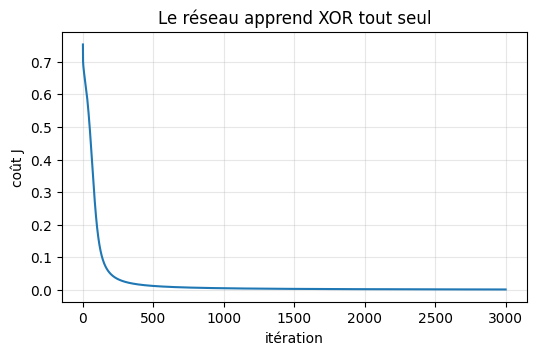

In [23]:
X = X_xor.T.astype(float)          # (2, 4) : un exemple par colonne, comme dans les slides
Y = y_xor.reshape(1, -1)           # (1, 4)
m = X.shape[1]

np.random.seed(2)                                        # le point de départ (voir la remarque après)
W1_x, b1_x = np.random.randn(3, 2), np.zeros((3, 1))     # couche cachée : 3 neurones
W2_x, b2_x = np.random.randn(1, 3), np.zeros((1, 1))     # sortie : 1 neurone
eta = 2.0
historique = []

for iteration in range(3000):
    # Forward
    A1 = sigmoid(W1_x @ X + b1_x)                         # (3, 4)
    A2 = sigmoid(W2_x @ A1 + b2_x)                        # (1, 4)
    historique.append(-np.mean(Y * np.log(A2) + (1 - Y) * np.log(1 - A2)))
    # Backward
    dZ2 = A2 - Y
    dW2_x, db2_x = dZ2 @ A1.T / m, dZ2.sum(axis=1, keepdims=True) / m
    dZ1 = (W2_x.T @ dZ2) * A1 * (1 - A1)
    dW1_x, db1_x = dZ1 @ X.T / m, dZ1.sum(axis=1, keepdims=True) / m
    # Mise à jour
    W1_x, b1_x = W1_x - eta * dW1_x, b1_x - eta * db1_x
    W2_x, b2_x = W2_x - eta * dW2_x, b2_x - eta * db2_x

print(f"Coût : {historique[0]:.3f} au départ  ->  {historique[-1]:.4f} à la fin")
print("Prédictions :", A2.ravel(), "  ->  classes :", (A2.ravel() >= 0.5).astype(int), "  XOR :", y_xor)

plt.figure(figsize=(6, 3.5))
plt.plot(historique)
plt.xlabel("itération"); plt.ylabel("coût J"); plt.grid(alpha=0.3)
plt.title("Le réseau apprend XOR tout seul")
plt.show()

**Remarque importante : le point de départ compte.** Remplace `np.random.seed(2)` par `np.random.seed(0)` et relance la cellule : le réseau reste **bloqué** avec un coût d'environ 0.35. Il classe bien deux points, mais répond 0.5 (« je ne sais pas ») pour les deux autres. La descente de gradient s'est arrêtée dans un **minimum local** : un creux qui n'est pas le plus bas. Avec un seul neurone (session 2), le coût était convexe (un seul creux) ; avec une couche cachée, ce n'est plus le cas. C'est pour ça que l'initialisation des poids est un vrai sujet en deep learning.

> ✅ **À retenir (exercice 3)**
>
> - **Forward** : $z^{[l]} = W^{[l]} a^{[l-1]} + b^{[l]}$, puis $a^{[l]} = \sigma(z^{[l]})$, couche après couche.
> - **Backward** : on part de l'erreur $dz^{[2]} = a^{[2]} - y$ et on remonte : $dW = dz \times (\text{entrée})^\top$, puis $da^{[l-1]} = W^{[l]\top} dz^{[l]}$ et $dz^{[l-1]} = da^{[l-1]} \odot a(1 - a)$.
> - Chaque gradient a **la forme de son paramètre** : la meilleure vérification quand on code.
> - `loss.backward()` en PyTorch calcule **exactement** ces gradients.

---
# 📝 Fiche résumé de la session 3

| Notion | Formule | En une phrase |
|---|---|---|
| XOR | $\text{XOR} = \text{AND}(\text{OR}, \text{NAND})$ | 2 neurones cachés tracent 2 droites, la sortie les combine |
| Forme des poids | $W^{[l]} : (n^{[l]}, n^{[l-1]})$, $b^{[l]} : n^{[l]}$ | (sortie, entrée), une ligne par neurone |
| Nombre de paramètres | $n^{[l]}(n^{[l-1]} + 1)$ par couche | des poids plus un biais par neurone |
| Forward | $Z^{[l]} = W^{[l]}A^{[l-1]} + b^{[l]}$, $A^{[l]} = \sigma(Z^{[l]})$ | chaque couche fait ce que faisait un neurone, pour tous ses neurones |
| En code (exemples en lignes) | `A @ W.T + b` | c'est ce que fait `nn.Linear` |
| Non-linéarité | $W^{[2]}(W^{[1]}x + b^{[1]}) + b^{[2]} = W'x + b'$ | sans activation, le réseau reste une seule droite |
| Erreur de sortie | $dZ^{[2]} = A^{[2]} - Y$ | comme en session 2 |
| Gradient des poids | $dW^{[l]} = \frac{1}{m}\, dZ^{[l]} A^{[l-1]\top}$ | erreur × entrée |
| Rétropropagation | $dZ^{[l]} = W^{[l+1]\top} dZ^{[l+1]} \odot A^{[l]}(1 - A^{[l]})$ | l'erreur remonte une couche à la fois |
| PyTorch | `nn.Sequential(nn.Linear(2, 3), nn.Sigmoid(), nn.Linear(3, 1))` + `loss.backward()` | le réseau et la backpropagation automatique |

**Prochaine session** : maîtriser tout le pipeline PyTorch, ligne par ligne.